Intro

Import libraries and load the dataset into a dataframe for analysis.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

rawdata="student-mat.csv"

df = pd.read_csv(rawdata, sep=";")

# 1 Exploratory Data Analysis
- We calculated summary statistics to quickly understand the grade distribution before creating visual representations. The results are calculated below.

In [10]:
finalGrades=df["G3"].values

# Calculate summary stats
mean = np.mean(finalGrades)
median = np.median(finalGrades)
standardDeviation = np.std(finalGrades)

print(f"Summary stastics:\n\tMean: {mean}\n\tMedian: {median}\n\tStandard Deviation: {standardDeviation}")

Summary stastics:
	Mean: 10.415189873417722
	Median: 11.0
	Standard Deviation: 4.57563964146053


## Observations
- The grade distribution appears approximately normal, except for a high concentration of failing grades.

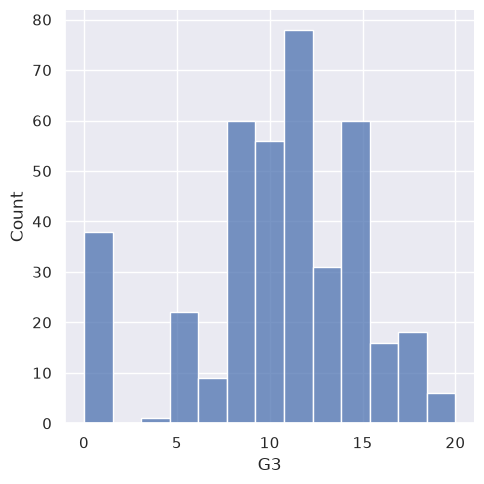

In [11]:
sns.set_theme()
histogram = sns.displot(data=df, x="G3")

In [ ]:
def normalizeParentalEducation(row):
	if row["Pstatus"] == "T":
		return (row["Fedu"] + row["Medu"])/2
	elif row["guardian"] == "mother":
		return row["Medu"]
	elif row["guardian"] == "father":
		return row["Fedu"]
	else:
		return 0
#applu normalization
df["normParentEdu"] = df.apply(normalizeParentalEducation, axis=1)
# discard input categories after normalization
df = df.drop(columns=["Medu","Fedu"]) 

We normalized the education of the parents to account for different custody situations and to average the education of two parent households. For example, ff a student is raised by their father, the education of the mother should not be considered.

In [28]:
correlations = df.corr(method="pearson", numeric_only=True)["G3"]
print((correlations.sort_values(ascending=False)*100).map("{:.2f}%".format))

G3               100.00%
G2                90.49%
G1                80.15%
normParentEdu     18.82%
studytime          9.78%
famrel             5.14%
absences           3.42%
freetime           1.13%
Walc              -5.19%
Dalc              -5.47%
health            -6.13%
traveltime       -11.71%
goout            -13.28%
age              -16.16%
failures         -36.04%
Name: G3, dtype: str


After normalizing the data set, we performed a Pearson's correlation analysis of each numerical category against the the final grade.

Our correlation analysis found that the preceeding semester averages had the strongest correlation with the final grade at 90% and 80% respectively. The number of past failures displayed a negative correlation of 36%. Our normalized parental education had an 18.82% correlation, the remaining attributes fell of quickly.

References
- https://www.geeksforgeeks.org/machine-learning/best-python-libraries-for-machine-learning/
- https://realpython.com/python-seaborn/
- https://seaborn.pydata.org/tutorial/distributions.html
- https://stackoverflow.com/a/34796529